# Task 6: Perbandingan Performa Apriori dan FP-Growth

Kedua algoritma dijalankan pada transactional database Author-Based yang sama (`tx_author_based.pkl`) dengan empat minimum support dari Task 4: 0,1%, 0,5%, 1%, dan 2%. Metrik yang diminta spesifikasi adalah **jumlah frequent itemset** dan **jumlah association rules** (min confidence 50%). Runtime dan peak memory ikut diukur karena dua metrik wajib itu tidak membedakan kedua algoritma bila keduanya benar.

Dua minimum support tambahan, 0,05% dan 0,03%, dijalankan di luar rentang spesifikasi. Tujuannya melihat apakah selisih runtime yang mengecil di 0,1% berlanjut menjadi kebalikan. Semua tabel memberi label `rentang` (`spec` atau `tambahan`) agar kedua kelompok tidak tercampur.

In [1]:
import gc
import math
import os
import platform
import statistics
import sys
import time
import tracemalloc
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append("..")
from src.apriori import run_apriori, _generate_candidates
from src.fpgrowth import run_fpgrowth, build_fp_tree, mine_patterns
from src.association_rules import generate_rules
from src.transactions import load_transactions

# True = tes pakai sampel 2024, False = data penuh 2015-2025
USE_SAMPLE = False

if USE_SAMPLE:
    TX_PATH = "../data/sample/tx_author_based_sample.pkl"
    SUFFIX = "_sample"
else:
    TX_PATH = "../data/processed/tx_author_based.pkl"
    SUFFIX = ""

FIGURES_DIR = "../figures"
STATS_OUT_DIR = "../data/results"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)

# parameter sama dengan task 4 dan task 5
MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
# di luar spec, hanya untuk melihat tren runtime saat min support makin kecil
EXTRA_SUPPORTS = [0.0005, 0.0003]
ALL_SUPPORTS = sorted(MIN_SUPPORTS + EXTRA_SUPPORTS)
MIN_CONFIDENCE = 0.5
N_RUNS = 3

ALGORITHMS = {"Apriori": run_apriori, "FP-Growth": run_fpgrowth}


def rentang(ms):
    return "spec" if ms in MIN_SUPPORTS else "tambahan"


# transactional db yang sama untuk kedua algoritma (author-based)
transactions = load_transactions(TX_PATH)
N = len(transactions)
print(f"Transaksi: {TX_PATH}")
print(f"Jumlah transaksi: {N:,}")
print(f"Lingkungan: Python {platform.python_version()} | {platform.processor()} | {os.cpu_count()} logical core | single-thread")

Transaksi: ../data/processed/tx_author_based.pkl
Jumlah transaksi: 1,821,757
Lingkungan: Python 3.14.5 | AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | 16 logical core | single-thread


## 1. Benchmark jumlah itemset, rules, runtime, dan memori

Runtime diambil sebagai median dari tiga kali jalan. Peak memory diukur di run terpisah dengan `tracemalloc` karena pelacakan alokasi memperlambat eksekusi; angka ini hanya mencakup alokasi objek Python. Peak memory hanya diukur pada empat nilai spec: percobaan dengan `tracemalloc` di 0,05% dan 0,03% belum selesai setelah 20 menit, sehingga kolom memori untuk dua nilai tambahan dibiarkan kosong. Association rules dibangkitkan dari frequent itemset hasil masing-masing algoritma, bukan dari satu hasil bersama.

In [2]:
# ukur runtime: jalankan N_RUNS kali lalu ambil median agar tidak terpengaruh fluktuasi
def measure_runtime(func, ms):
    times = []
    for _ in range(N_RUNS):
        gc.collect()
        t0 = time.perf_counter()
        result = func(transactions, ms)
        times.append(time.perf_counter() - t0)
    return result, statistics.median(times), times

# ukur peak memory di run terpisah karena tracemalloc memperlambat eksekusi
def measure_peak_memory(func, ms):
    gc.collect()
    tracemalloc.start()
    func(transactions, ms)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 2**20

itemsets = {}
rows = []
for ms in ALL_SUPPORTS:
    for name, func in ALGORITHMS.items():
        result, median_s, all_s = measure_runtime(func, ms)
        # tracemalloc terlalu lambat di min support tambahan, memori hanya diukur di rentang spec
        peak_mb = measure_peak_memory(func, ms) if ms in MIN_SUPPORTS else np.nan

        t0 = time.perf_counter()
        rules = generate_rules(result, N, MIN_CONFIDENCE)
        rules_s = time.perf_counter() - t0

        itemsets[(ms, name)] = (result, rules)
        rows.append({
            "min_support": ms,
            "rentang": rentang(ms),
            "algoritma": name,
            "jumlah_itemset": len(result),
            "jumlah_rules": len(rules),
            "runtime_median_s": round(median_s, 3),
            "runtime_min_s": round(min(all_s), 3),
            "runtime_max_s": round(max(all_s), 3),
            "peak_memory_mb": round(peak_mb, 1) if ms in MIN_SUPPORTS else np.nan,
            "rules_runtime_s": round(rules_s, 3),
        })
        print(f"min_support={ms:<6} | {name:<9} | itemset={len(result):>6,} | rules={len(rules):>6,} | {median_s:6.2f}s | {peak_mb:7.1f} MB", flush=True)

benchmark = pd.DataFrame(rows)
benchmark.to_csv(f"{STATS_OUT_DIR}/task6_benchmark{SUFFIX}.csv", index=False)

min_support=0.0003 | Apriori   | itemset=16,195 | rules=52,428 |  56.18s |     nan MB


min_support=0.0003 | FP-Growth | itemset=16,195 | rules=52,428 |  26.76s |     nan MB


min_support=0.0005 | Apriori   | itemset= 5,657 | rules=10,865 |  30.82s |     nan MB


min_support=0.0005 | FP-Growth | itemset= 5,657 | rules=10,865 |  22.37s |     nan MB


min_support=0.001  | Apriori   | itemset= 1,514 | rules= 1,387 |  11.98s |    87.9 MB


min_support=0.001  | FP-Growth | itemset= 1,514 | rules= 1,387 |  12.08s |   267.0 MB


... (2 outputs left out)

min_support=0.01   | Apriori   | itemset=    30 | rules=     1 |   2.41s |     4.2 MB


min_support=0.01   | FP-Growth | itemset=    30 | rules=     1 |   3.27s |    15.3 MB


min_support=0.02   | Apriori   | itemset=     6 | rules=     0 |   1.97s |     0.2 MB


min_support=0.02   | FP-Growth | itemset=     6 | rules=     0 |   2.69s |     0.2 MB


## 2. Apakah kedua algoritma menghasilkan frequent itemset yang sama?

Perbandingan dilakukan pada tiga tingkat: himpunan itemset, support count tiap itemset, dan seluruh rules beserta nilai support, confidence, dan lift.

In [3]:
def rules_key(df):
    return sorted(
        (tuple(sorted(a)), tuple(sorted(c)), round(s, 12), round(cf, 12), round(l, 12))
        for a, c, s, cf, l in df[["antecedents", "consequents", "support", "confidence", "lift"]].itertuples(index=False)
    )

check_rows = []
for ms in ALL_SUPPORTS:
    ap_items, ap_rules = itemsets[(ms, "Apriori")]
    fp_items, fp_rules = itemsets[(ms, "FP-Growth")]
    check_rows.append({
        "min_support": ms,
        "rentang": rentang(ms),
        "min_count": math.ceil(ms * N),
        "itemset_apriori": len(ap_items),
        "itemset_fpgrowth": len(fp_items),
        "itemset_sama": set(ap_items) == set(fp_items),
        "support_count_sama": ap_items == fp_items,
        "hanya_di_apriori": len(set(ap_items) - set(fp_items)),
        "hanya_di_fpgrowth": len(set(fp_items) - set(ap_items)),
        "rules_apriori": len(ap_rules),
        "rules_fpgrowth": len(fp_rules),
        "rules_sama": rules_key(ap_rules) == rules_key(fp_rules),
    })

consistency = pd.DataFrame(check_rows)
consistency.to_csv(f"{STATS_OUT_DIR}/task6_consistency{SUFFIX}.csv", index=False)
consistency

,min_support,rentang,min_count,itemset_apriori,itemset_fpgrowth,itemset_sama,support_count_sama,hanya_di_apriori,hanya_di_fpgrowth,rules_apriori,rules_fpgrowth,rules_sama
0,0.0003,tambahan,547,16195,16195,True,True,0,0,52428,52428,True
1,0.0005,tambahan,911,5657,5657,True,True,0,0,10865,10865,True
2,0.0010,spec,1822,1514,1514,True,True,0,0,1387,1387,True
3,0.0050,spec,9109,88,88,True,True,0,0,7,7,True
4,0.0100,spec,18218,30,30,True,True,0,0,1,1,True
5,0.0200,spec,36436,6,6,True,True,0,0,0,0,True


## 3. Jumlah frequent itemset dan rules per ukuran itemset

Karena hasil kedua algoritma identik, rincian ini cukup dihitung dari satu hasil. Tabel kedua menunjukkan dari ukuran itemset berapa rules berasal, untuk menjelaskan mengapa jumlah rules turun jauh lebih tajam daripada jumlah itemset.

In [4]:
size_rows, rule_rows = [], []
for ms in ALL_SUPPORTS:
    result, rules = itemsets[(ms, "Apriori")]
    item_sizes = Counter(len(s) for s in result)
    rule_sizes = Counter(len(a) + len(c) for a, c in zip(rules["antecedents"], rules["consequents"]))
    max_k = max(item_sizes)
    size_rows.append({"min_support": ms, "rentang": rentang(ms), **{f"{k}-itemset": item_sizes.get(k, 0) for k in range(1, max_k + 1)}})
    rule_rows.append({
        "min_support": ms,
        "rentang": rentang(ms),
        "itemset_ukuran_2_ke_atas": sum(v for k, v in item_sizes.items() if k >= 2),
        "jumlah_rules": len(rules),
        **{f"rules_dari_{k}-itemset": rule_sizes.get(k, 0) for k in range(2, max_k + 1)},
    })

itemset_sizes = pd.DataFrame(size_rows).fillna(0)
num_cols = itemset_sizes.columns.drop(["min_support", "rentang"])
itemset_sizes[num_cols] = itemset_sizes[num_cols].astype(int)

rules_by_size = pd.DataFrame(rule_rows).fillna(0)
num_cols = rules_by_size.columns.drop(["min_support", "rentang"])
rules_by_size[num_cols] = rules_by_size[num_cols].astype(int)
# rules per itemset berukuran >= 2: seberapa banyak itemset yang lolos menjadi rule
rules_by_size["rules_per_itemset_k2plus"] = (
    rules_by_size["jumlah_rules"] / rules_by_size["itemset_ukuran_2_ke_atas"].replace(0, np.nan)
).round(2)

itemset_sizes.to_csv(f"{STATS_OUT_DIR}/task6_itemset_sizes{SUFFIX}.csv", index=False)
rules_by_size.to_csv(f"{STATS_OUT_DIR}/task6_rules_by_size{SUFFIX}.csv", index=False)
display(itemset_sizes)
display(rules_by_size)

,min_support,rentang,1-itemset,2-itemset,3-itemset,4-itemset,5-itemset,6-itemset,7-itemset,8-itemset
0,0.0003,tambahan,1697,2696,3629,3981,2763,1158,251,20
1,0.0005,tambahan,1185,1219,1382,1152,575,133,11,0
2,0.0010,spec,574,393,348,159,37,3,0,0
3,0.0050,spec,66,21,1,0,0,0,0,0
4,0.0100,spec,29,1,0,0,0,0,0,0
5,0.0200,spec,6,0,0,0,0,0,0,0


,min_support,rentang,itemset_ukuran_2_ke_atas,jumlah_rules,rules_dari_2-itemset,rules_dari_3-itemset,rules_dari_4-itemset,rules_dari_5-itemset,rules_dari_6-itemset,rules_dari_7-itemset,rules_dari_8-itemset,rules_per_itemset_k2plus
0,0.0003,tambahan,14498,52428,60,3034,10121,16446,14831,6786,1150,3.62
1,0.0005,tambahan,4472,10865,40,1414,3259,3804,1989,359,0,2.43
2,0.0010,spec,940,1387,22,436,555,313,61,0,0,1.48
3,0.0050,spec,22,7,4,3,0,0,0,0,0,0.32
4,0.0100,spec,1,1,1,0,0,0,0,0,0,1.00
5,0.0200,spec,0,0,0,0,0,0,0,0,0,NaN


## 4. Tabel perbandingan per minimum support

Rasio di atas 1 berarti FP-Growth lebih cepat atau lebih hemat memori.

In [5]:
comparison = benchmark.pivot(
    index="min_support",
    columns="algoritma",
    values=["jumlah_itemset", "jumlah_rules", "runtime_median_s", "peak_memory_mb"],
)
comparison.columns = [f"{metric} ({algo})" for metric, algo in comparison.columns]

comparison["speedup FP-Growth vs Apriori"] = (
    comparison["runtime_median_s (Apriori)"] / comparison["runtime_median_s (FP-Growth)"]
).round(2)
comparison["rasio memori Apriori / FP-Growth"] = (
    comparison["peak_memory_mb (Apriori)"] / comparison["peak_memory_mb (FP-Growth)"]
).round(2)

comparison = comparison.reset_index()
comparison.insert(1, "rentang", comparison["min_support"].map(rentang))
comparison.to_csv(f"{STATS_OUT_DIR}/task6_comparison{SUFFIX}.csv", index=False)
comparison.T

,0,1,2,3,4,5
min_support,0.0003,0.0005,0.001,0.005,0.01,0.02
rentang,tambahan,tambahan,spec,spec,spec,spec
jumlah_itemset (Apriori),16195.0,5657.0,1514.0,88.0,30.0,6.0
jumlah_itemset (FP-Growth),16195.0,5657.0,1514.0,88.0,30.0,6.0
jumlah_rules (Apriori),52428.0,10865.0,1387.0,7.0,1.0,0.0
jumlah_rules (FP-Growth),52428.0,10865.0,1387.0,7.0,1.0,0.0
runtime_median_s (Apriori),56.177,30.825,11.977,2.701,2.415,1.967
runtime_median_s (FP-Growth),26.756,22.367,12.077,4.298,3.275,2.691
peak_memory_mb (Apriori),NaN,NaN,87.9,10.8,4.2,0.2
peak_memory_mb (FP-Growth),NaN,NaN,267.0,49.2,15.3,0.2


## 5. Beban kerja di dalam tiap algoritma

Jumlah itemset dan rules tidak menjelaskan mengapa runtime kedua algoritma berbeda. Bagian ini mengukur apa yang sebenarnya dikerjakan masing-masing algoritma.

- **Apriori** (`src/apriori.py`) memindai seluruh transaksi sekali untuk menghitung 1-itemset, lalu meng-encode setiap transaksi menjadi tuple ID item frequent. Transaksi dengan kurang dari dua item frequent dibuang, dan tuple yang sama digabung dengan bobot. Level 2 dan seterusnya hanya bekerja pada tuple unik ini. Fase pertama ditiru di sel berikut agar waktunya bisa dipisah; waktu level-wise = runtime total `run_apriori` dikurangi fase pertama.
- **FP-Growth** (`src/fpgrowth.py`) terdiri dari dua fungsi yang bisa diukur langsung: `build_fp_tree` (hitung item lalu sisipkan setiap transaksi ke tree) dan `mine_patterns` (bangun conditional tree secara rekursif).

Semua waktu di bagian ini, termasuk total `run_apriori`, diukur ulang di sel ini agar fase dan total berasal dari kondisi mesin yang sama. Angkanya bisa sedikit berbeda dari tabel benchmark di bagian 1. Waktu di empat nilai spec adalah median tiga kali jalan; di dua nilai tambahan hanya sekali jalan.

In [6]:
def apriori_first_pass(ms):
    # tiruan baris awal run_apriori: hitung item, encode, buang transaksi < 2 item, gabung tuple sama
    min_count = math.ceil(ms * N)
    item_counts = Counter(item for t in transactions for item in t)
    freq_items = sorted(item for item, c in item_counts.items() if c >= min_count)
    item_to_id = {item: j for j, item in enumerate(freq_items)}
    weighted_tx = Counter()
    freq_occurrences = 0
    for t in transactions:
        encoded = tuple(sorted(item_to_id[item] for item in t if item in item_to_id))
        freq_occurrences += len(encoded)
        if len(encoded) >= 2:
            weighted_tx[encoded] += 1
    return freq_items, item_to_id, weighted_tx, freq_occurrences


def count_nodes(root):
    stack, n = [root], 0
    while stack:
        node = stack.pop()
        n += 1
        stack.extend(node.children.values())
    return n - 1  # root tidak dihitung


def median_time(fn, runs=N_RUNS):
    times, out = [], None
    for _ in range(runs):
        gc.collect()
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return out, statistics.median(times)


workload_rows, encodings = [], {}
for ms in ALL_SUPPORTS:
    min_count = math.ceil(ms * N)
    # min support tambahan cukup sekali jalan agar notebook tidak terlalu lama
    runs = N_RUNS if ms in MIN_SUPPORTS else 1
    (freq_items, item_to_id, weighted_tx, freq_occ), t_first = median_time(lambda: apriori_first_pass(ms), runs)
    encodings[ms] = item_to_id
    _, ap_total = median_time(lambda: run_apriori(transactions, ms), runs)
    (root, header), t_build = median_time(lambda: build_fp_tree(transactions, ms), runs)
    _, t_mine = median_time(lambda: mine_patterns(header, min_count), runs)
    n_nodes = count_nodes(root)

    workload_rows.append({
        "min_support": ms,
        "rentang": rentang(ms),
        "frequent_1_itemset": len(freq_items),
        "transaksi_min_2_item_frequent": sum(weighted_tx.values()),
        "persen_transaksi_dipakai_level2": round(100 * sum(weighted_tx.values()) / N, 1),
        "tuple_unik_apriori": len(weighted_tx),
        "apriori_first_pass_s": round(t_first, 3),
        "apriori_levelwise_s": round(max(ap_total - t_first, 0), 3),
        "apriori_total_s": round(ap_total, 3),
        "kemunculan_item_frequent": freq_occ,
        "node_fptree": n_nodes,
        "node_per_kemunculan": round(n_nodes / freq_occ, 3) if freq_occ else np.nan,
        "fp_build_tree_s": round(t_build, 3),
        "fp_mining_s": round(t_mine, 3),
        "fp_total_s": round(t_build + t_mine, 3),
    })
    del root, header

workload = pd.DataFrame(workload_rows)
workload.to_csv(f"{STATS_OUT_DIR}/task6_workload{SUFFIX}.csv", index=False)
workload.T

,0,1,2,3,4,5
min_support,0.0003,0.0005,0.001,0.005,0.01,0.02
rentang,tambahan,tambahan,spec,spec,spec,spec
frequent_1_itemset,1697,1185,574,66,29,6
transaksi_min_2_item_frequent,696439,648442,536596,239256,159627,42103
persen_transaksi_dipakai_level2,38.2,35.6,29.5,13.1,8.8,2.3
tuple_unik_apriori,485502,432645,315731,74569,28264,57
apriori_first_pass_s,3.296,3.093,2.628,2.2,2.071,1.886
apriori_levelwise_s,49.811,21.949,8.088,0.391,0.07,0.012
apriori_total_s,53.107,25.042,10.716,2.591,2.142,1.898
kemunculan_item_frequent,4365057,4002911,3207893,1368202,883137,271160


### Kandidat Apriori per level

Kandidat level k dibangkitkan dari frequent (k-1)-itemset dengan fungsi `_generate_candidates` yang sama dengan `run_apriori`, sehingga jumlahnya sama dengan yang dihitung algoritma. Persentase lolos yang tinggi berarti Apriori jarang membuang waktu menghitung kandidat yang ternyata tidak frequent.

In [7]:
cand_rows = []
n_unique_items = len({item for t in transactions for item in t})
for ms in ALL_SUPPORTS:
    result, _ = itemsets[(ms, "Apriori")]
    item_to_id = encodings[ms]
    by_level = {}
    for s in result:
        by_level.setdefault(len(s), []).append(tuple(sorted(item_to_id[i] for i in s)))

    cand_rows.append({"min_support": ms, "rentang": rentang(ms), "k": 1, "kandidat": n_unique_items, "frequent": len(by_level.get(1, []))})
    k = 2
    while by_level.get(k - 1):
        candidates = _generate_candidates(sorted(by_level[k - 1]), k)
        if not candidates:
            break
        cand_rows.append({"min_support": ms, "rentang": rentang(ms), "k": k, "kandidat": len(candidates), "frequent": len(by_level.get(k, []))})
        k += 1

apriori_candidates = pd.DataFrame(cand_rows)
apriori_candidates["persen_lolos"] = (100 * apriori_candidates["frequent"] / apriori_candidates["kandidat"]).round(1)
apriori_candidates.to_csv(f"{STATS_OUT_DIR}/task6_apriori_candidates{SUFFIX}.csv", index=False)
apriori_candidates.pivot_table(index="k", columns="min_support", values=["kandidat", "frequent"], aggfunc="sum").fillna(0).astype(int)

frequent                                    kandidat          \
min_support   0.0003 0.0005 0.0010 0.0050 0.0100 0.0200   0.0003  0.0005   
k                                                                          
1               1697   1185    574     66     29      6     4372    4372   
2               2696   1219    393     21      1      0  1439056  701520   
3               3629   1382    348      1      0      0    19450    6052   
4               3981   1152    159      0      0      0     8129    2237   
5               2763    575     37      0      0      0     4339     871   
6               1158    133      3      0      0      0     1578     188   
7                251     11      0      0      0      0      340      15   
8                 20      0      0      0      0      0       29       0   

                                          
min_support  0.0010 0.0050 0.0100 0.0200  
k                                         
1              4372   4372   4372   4372  
2            164451   2145    406     15  
3              1228     13      0      0  
4               337      0      0      0  
5                54      0      0      0  
6                 5      0      0      0  
7                 0      0      0      0  
8                 0      0      0      0

## 6. Visualisasi

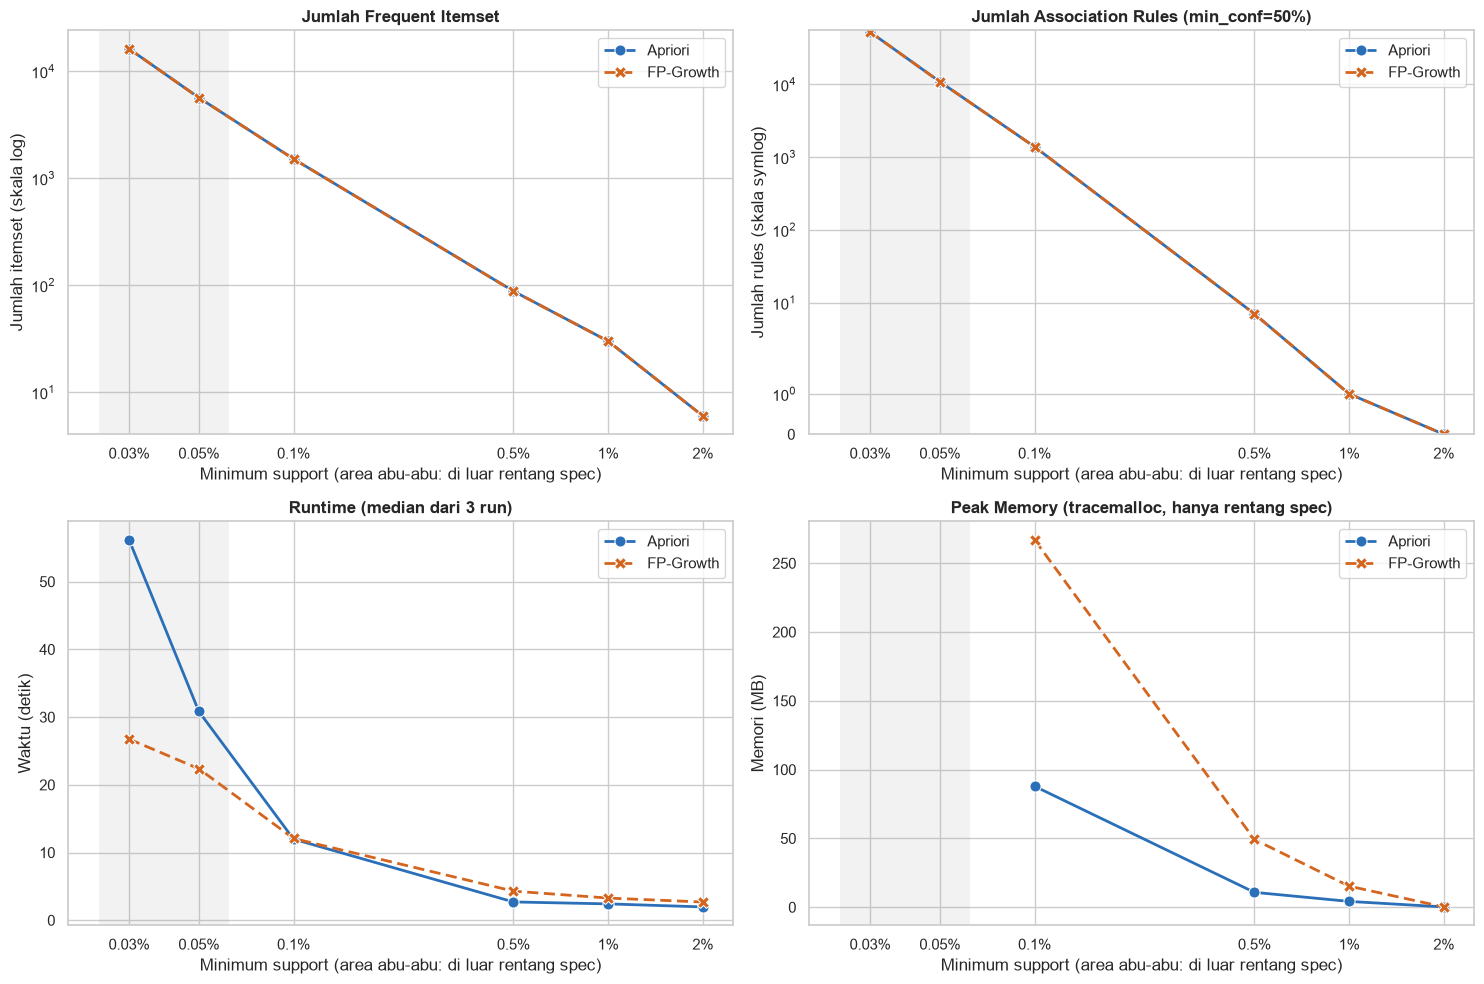

In [8]:
sns.set_theme(style="whitegrid")
palette = {"Apriori": "#2a6fb8", "FP-Growth": "#d4651f"}
xticklabels = [f"{ms * 100:g}%" for ms in ALL_SUPPORTS]


def shade_extra(ax):
    # area di luar rentang spec
    ax.axvspan(min(EXTRA_SUPPORTS) / 1.25, max(EXTRA_SUPPORTS) * 1.25, color="#9a9a9a", alpha=0.12, lw=0)


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [
    ("jumlah_itemset", "Jumlah Frequent Itemset", "Jumlah itemset (skala log)", "log"),
    ("jumlah_rules", f"Jumlah Association Rules (min_conf={MIN_CONFIDENCE:.0%})", "Jumlah rules (skala symlog)", "symlog"),
    ("runtime_median_s", f"Runtime (median dari {N_RUNS} run)", "Waktu (detik)", None),
    ("peak_memory_mb", "Peak Memory (tracemalloc, hanya rentang spec)", "Memori (MB)", None),
]

for ax, (col, title, ylabel, yscale) in zip(axes.flat, panels):
    shade_extra(ax)
    sns.lineplot(data=benchmark, x="min_support", y=col, hue="algoritma", style="algoritma",
                 markers=True, dashes=[(1, 0), (4, 2)], palette=palette, markersize=8, linewidth=2, ax=ax)
    ax.set_xscale("log")
    ax.set_xticks(ALL_SUPPORTS)
    ax.set_xticklabels(xticklabels)
    ax.minorticks_off()
    if yscale:
        ax.set_yscale(yscale)
        if yscale == "symlog":
            ax.set_ylim(bottom=0)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Minimum support (area abu-abu: di luar rentang spec)")
    ax.set_ylabel(ylabel)
    ax.legend(title=None)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task6_algorithm_comparison{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()

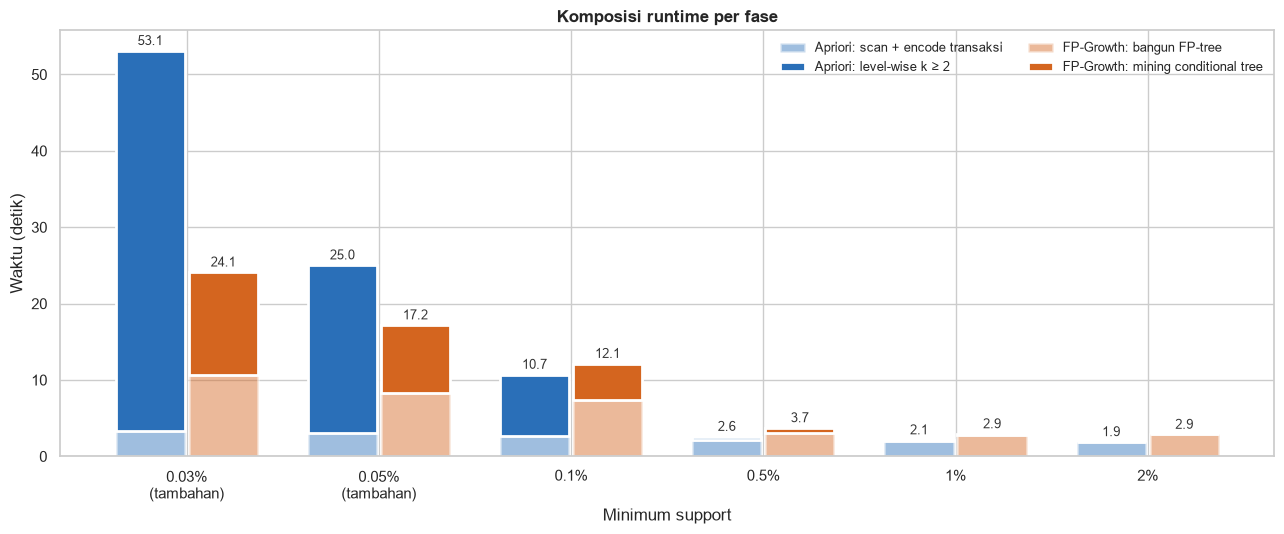

In [9]:
# komposisi runtime: fase awal (biaya tetap terhadap jumlah transaksi) vs fase mining
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(ALL_SUPPORTS))
w = 0.38
wl = workload.set_index("min_support").loc[ALL_SUPPORTS]

segments = [
    ("Apriori", -w / 2, wl["apriori_first_pass_s"], wl["apriori_levelwise_s"], "scan + encode transaksi", "level-wise k ≥ 2"),
    ("FP-Growth", w / 2, wl["fp_build_tree_s"], wl["fp_mining_s"], "bangun FP-tree", "mining conditional tree"),
]
for name, offset, first, second, lab1, lab2 in segments:
    color = palette[name]
    ax.bar(x + offset, first, w - 0.02, color=color, alpha=0.45, edgecolor="white", linewidth=2, label=f"{name}: {lab1}")
    ax.bar(x + offset, second, w - 0.02, bottom=first, color=color, edgecolor="white", linewidth=2, label=f"{name}: {lab2}")
    for xi, total in zip(x + offset, first + second):
        ax.text(xi, total + 0.4, f"{total:.1f}", ha="center", va="bottom", fontsize=9, color="#333333")

ax.set_xticks(x)
ax.set_xticklabels([f"{ms * 100:g}%" + ("\n(tambahan)" if ms in EXTRA_SUPPORTS else "") for ms in ALL_SUPPORTS])
ax.set_xlabel("Minimum support")
ax.set_ylabel("Waktu (detik)")
ax.set_title("Komposisi runtime per fase", fontsize=12, fontweight="bold")
ax.legend(ncol=2, fontsize=9, frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task6_runtime_breakdown{SUFFIX}.png", dpi=300, bbox_inches="tight")
plt.show()